# S02 EDA Preprocesamiento
Un fondo de inversión necesita un modelo que prediga el valor medio de las viviendas en diferentes zonas de California. 

In [1]:
# Python ≥3.7
import sys
assert sys.version_info >= (3, 7)

In [2]:
# Scikit-Learn ≥0.20
import sklearn
assert sklearn.__version__ >= "0.20"

In [3]:
# Importaciones comunes
import numpy as np
import os

In [4]:
# Formatear las figuras para que se vean mejor
%matplotlib inline
import matplotlib as mpl

mpl.rc('axes', labelsize=14)
mpl.rc('xtick', labelsize=12)
mpl.rc('ytick', labelsize=12)

In [5]:
import os
import tarfile
import urllib.request

DOWNLOAD_ROOT = "https://raw.githubusercontent.com/ageron/handson-ml2/master/"
HOUSING_PATH = os.path.join("datasets", "housing")
HOUSING_URL = DOWNLOAD_ROOT + "datasets/housing/housing.tgz"

In [6]:
def fetch_housing_data(housing_url=HOUSING_URL, housing_path=HOUSING_PATH):
    if not os.path.isdir(housing_path):
        os.makedirs(housing_path)
    tgz_path = os.path.join(housing_path, "housing.tgz")
    urllib.request.urlretrieve(housing_url, tgz_path)
    housing_tgz = tarfile.open(tgz_path)
    housing_tgz.extractall(path=housing_path)
    housing_tgz.close()

fetch_housing_data()

In [7]:
import pandas as pd

def load_housing_data(housing_path=HOUSING_PATH):
    csv_path = os.path.join(housing_path, "housing.csv")
    return pd.read_csv(csv_path)

housing = load_housing_data()

In [ ]:
housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,6.984127,0.146591,2.555556
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,6.238137,0.155797,2.109842
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,8.288136,0.129516,2.802260
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,5.817352,0.184458,2.547945
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,6.281853,0.172096,2.181467
...,...,...,...,...,...,...,...,...,...,...,...,...,...
20378,-122.04,38.68,26.0,1113.0,222.0,689.0,234.0,3.0486,83600.0,INLAND,4.756410,0.199461,2.944444
20379,-122.03,38.69,23.0,1796.0,380.0,939.0,330.0,2.7955,96300.0,INLAND,5.442424,0.211581,2.845455
20380,-121.60,39.15,19.0,1396.0,336.0,940.0,309.0,1.5208,70300.0,INLAND,4.517799,0.240688,3.042071
20381,-121.59,39.15,5.0,1922.0,489.0,938.0,439.0,2.0474,61300.0,INLAND,4.378132,0.254422,2.136674


In [9]:
housing.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [10]:
housing.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


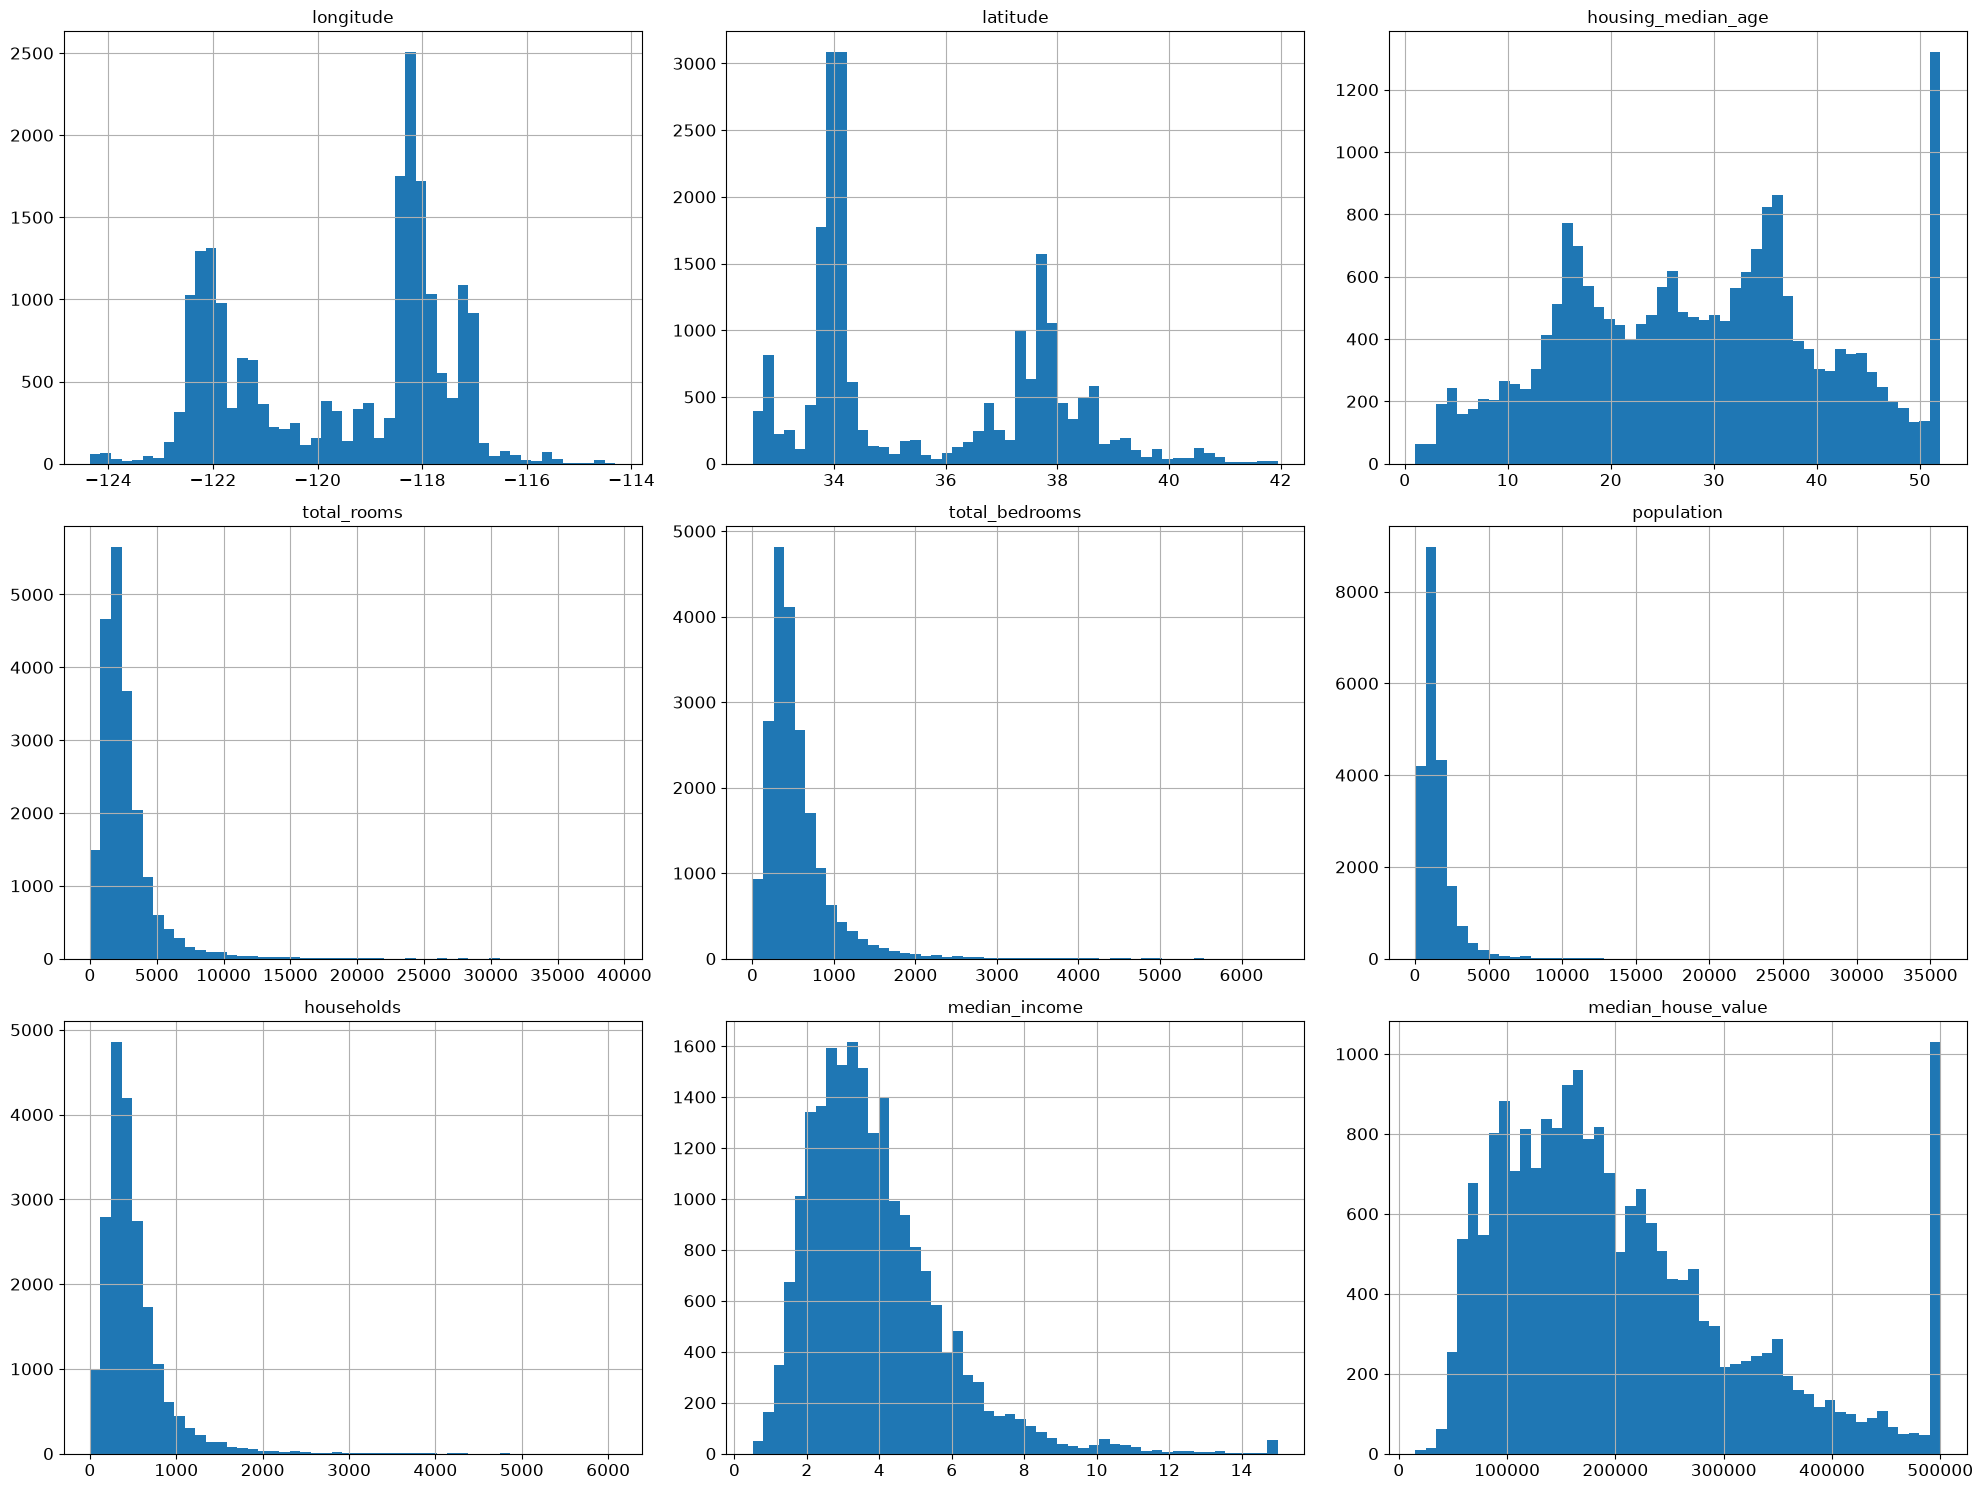

In [11]:
import matplotlib.pyplot as plt

housing.hist(bins=50, figsize=(20,15))
plt.tight_layout()

### Interpretación de los histogramas

Los histogramas muestran la distribución de cada variable numérica del dataset:

- **longitude y latitude:**  
  La distribución no es uniforme, hay agrupaciones claras que reflejan la concentración de viviendas en ciertas zonas geográficas de California.

- **housing_median_age:**  
  Hay dos picos principales y un gran número de viviendas con la edad máxima (50 años), lo que sugiere que muchas viviendas antiguas están agrupadas en ese valor, posiblemente por un límite en los datos.

- **total_rooms, total_bedrooms, population, households:**  
  Todas estas variables presentan una distribución sesgada a la derecha (muchos valores bajos y pocos valores muy altos). Esto indica que la mayoría de los distritos tienen pocos cuartos, dormitorios, habitantes y hogares, pero existen algunos con valores muy altos.

- **median_income:**  
  La mayoría de los ingresos medianos están entre 2 y 6 (en decenas de miles de dólares), con pocos distritos de ingresos muy altos.

- **median_house_value:**  
  La distribución es asimétrica y tiene un corte brusco en 500,000, lo que indica un límite artificial en el valor de las viviendas (capping).

**Conclusión:**  
Las variables presentan distribuciones no normales, muchas con sesgo a la derecha y algunas con límites artificiales. Esto es importante para el preprocesamiento y la selección de modelos, ya que puede ser necesario transformar algunas variables o tratar los valores extremos.

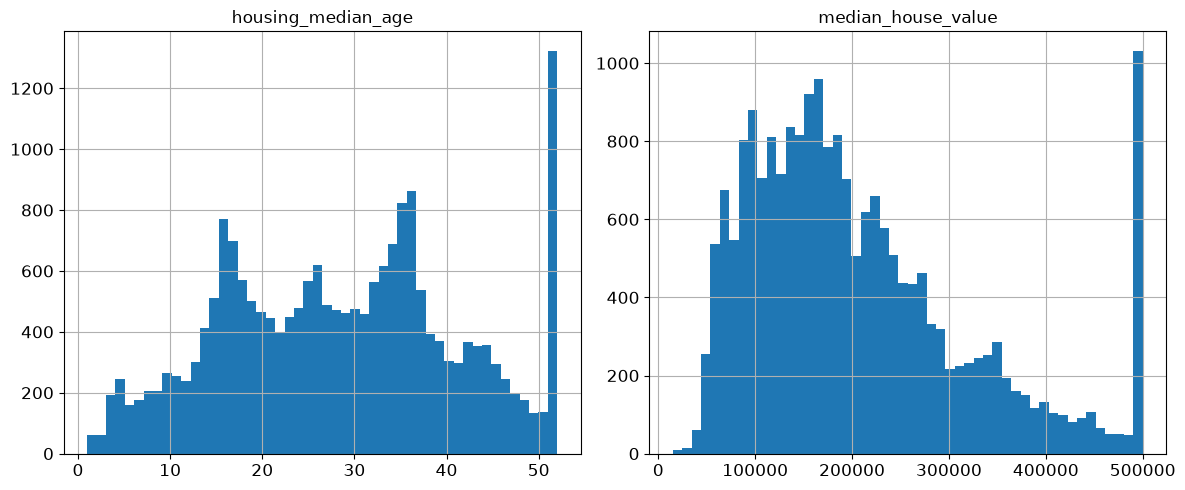

In [12]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

housing['housing_median_age'].hist(bins=50, ax=axes[0])
axes[0].set_title('housing_median_age')

housing['median_house_value'].hist(bins=50, ax=axes[1])
axes[1].set_title('median_house_value')

plt.tight_layout()
plt.show()

C:\Users\magal\AppData\Local\Temp\ipykernel_30808\2774050306.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, 0].boxplot(housing['housing_median_age'], vert=False)
C:\Users\magal\AppData\Local\Temp\ipykernel_30808\2774050306.py:16: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, 1].boxplot(housing['median_house_value'], vert=False)


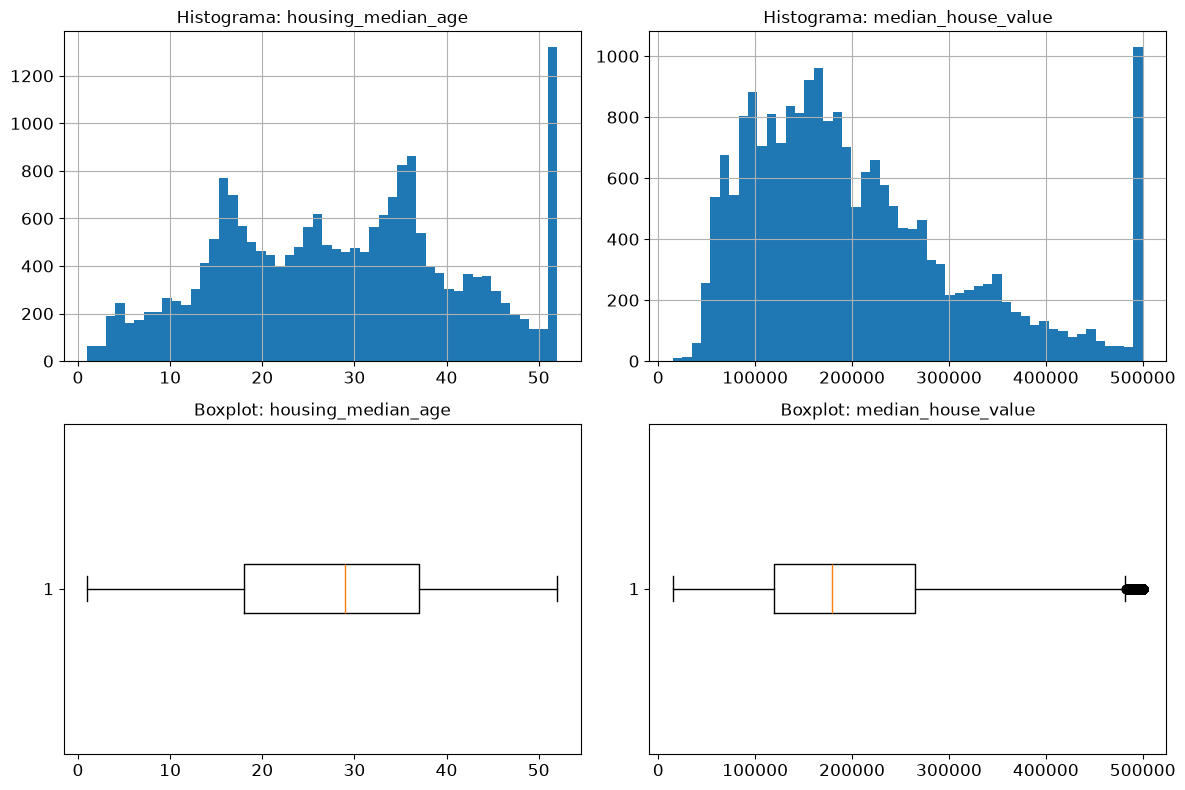

In [13]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Histogramas
housing['housing_median_age'].hist(bins=50, ax=axes[0, 0])
axes[0, 0].set_title('Histograma: housing_median_age')

housing['median_house_value'].hist(bins=50, ax=axes[0, 1])
axes[0, 1].set_title('Histograma: median_house_value')

# Boxplots
axes[1, 0].boxplot(housing['housing_median_age'], vert=False)
axes[1, 0].set_title('Boxplot: housing_median_age')

axes[1, 1].boxplot(housing['median_house_value'], vert=False)
axes[1, 1].set_title('Boxplot: median_house_value')

plt.tight_layout()
plt.show()

In [20]:
# Limitar valores extremos de median_house_value al percentil 99
upper_limit = housing['median_house_value'].quantile(0.99)
housing['median_house_value_capped'] = np.where(
    housing['median_house_value'] > upper_limit,
    upper_limit,
    housing['median_house_value']
)

C:\Users\magal\AppData\Local\Temp\ipykernel_30808\3064696870.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, 0].boxplot(housing['housing_median_age'], vert=False)
C:\Users\magal\AppData\Local\Temp\ipykernel_30808\3064696870.py:16: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, 1].boxplot(housing['median_house_value_capped'], vert=False)


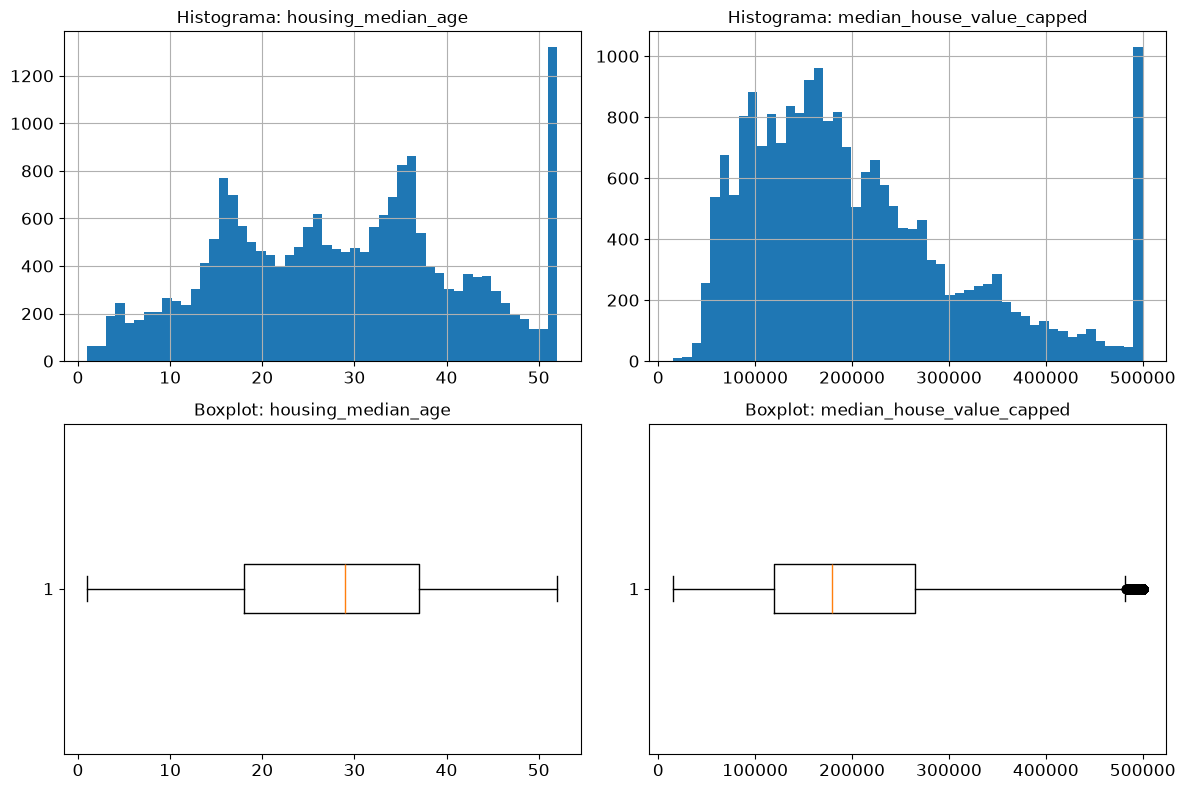

In [21]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Histogramas
housing['housing_median_age'].hist(bins=50, ax=axes[0, 0])
axes[0, 0].set_title('Histograma: housing_median_age')

housing['median_house_value_capped'].hist(bins=50, ax=axes[0, 1])
axes[0, 1].set_title('Histograma: median_house_value_capped')

# Boxplots
axes[1, 0].boxplot(housing['housing_median_age'], vert=False)
axes[1, 0].set_title('Boxplot: housing_median_age')

axes[1, 1].boxplot(housing['median_house_value_capped'], vert=False)
axes[1, 1].set_title('Boxplot: median_house_value_capped')

plt.tight_layout()
plt.show()

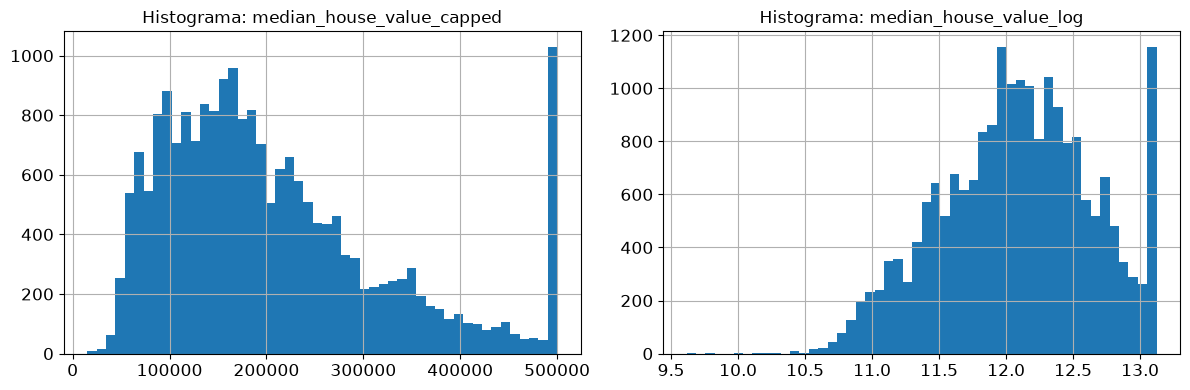

In [22]:
# Aplicar transformación logarítmica a median_house_value_capped
housing['median_house_value_log'] = np.log1p(housing['median_house_value_capped'])

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

housing['median_house_value_capped'].hist(bins=50, ax=axes[0])
axes[0].set_title('Histograma: median_house_value_capped')

housing['median_house_value_log'].hist(bins=50, ax=axes[1])
axes[1].set_title('Histograma: median_house_value_log')

plt.tight_layout()
plt.show()

# Multivariable

In [ ]:
corr_matrix = housing.corr()
corr_matrix["median_house_value"].sort_values(ascending=False)

In [27]:
housing = load_housing_data()

# Calcular la matriz de correlación solo con columnas numéricas
corr_matrix = housing.select_dtypes(include=[np.number]).corr()
corr_matrix["median_house_value"].sort_values(ascending=False)

median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64

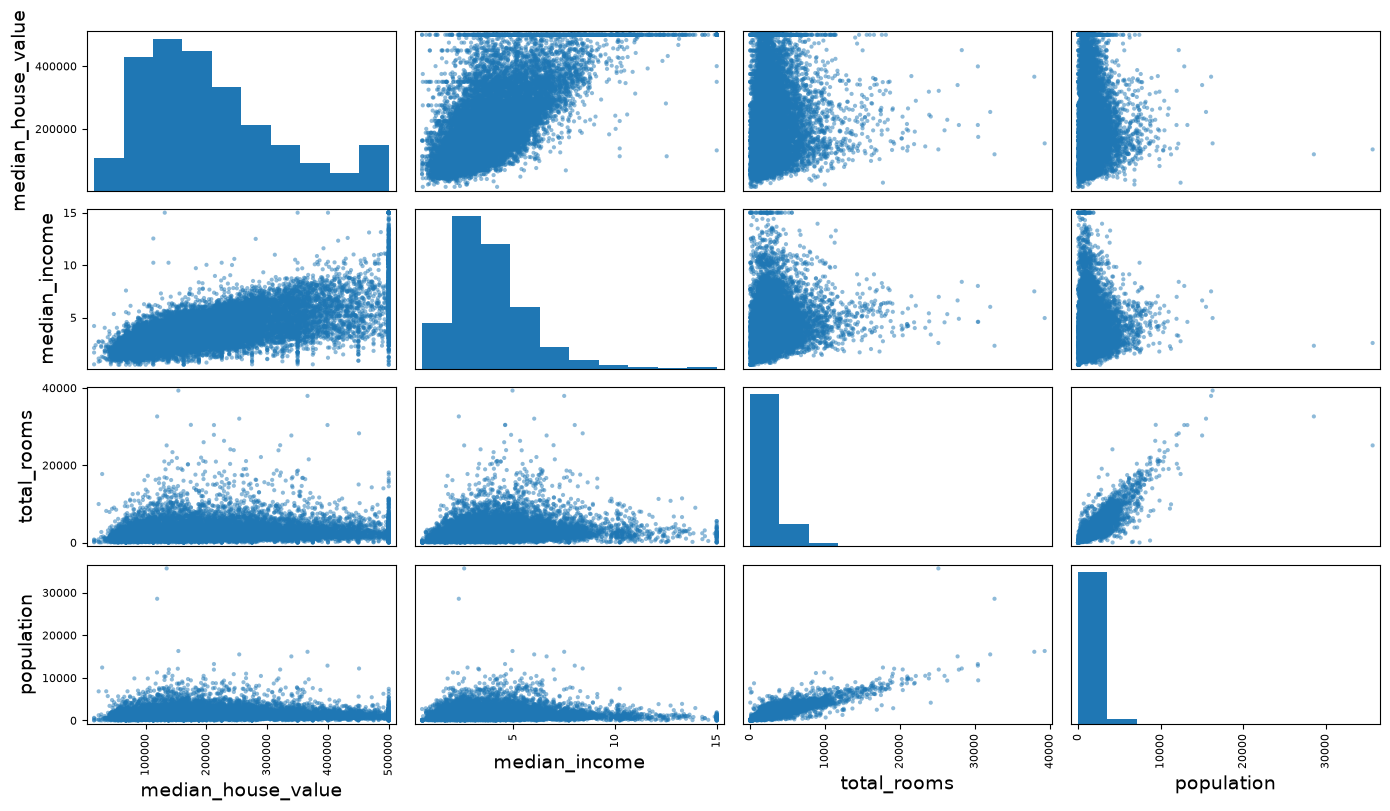

In [32]:
from pandas.plotting import scatter_matrix

attributes = ["median_house_value", "median_income", "total_rooms", "population"]
scatter_matrix(housing[attributes], figsize=(14, 8))
plt.tight_layout()

### Interpretación de la matriz de dispersión

La matriz de dispersión muestra la relación entre las variables `median_house_value`, `median_income`, `total_rooms` y `housing_median_age`:

- **En la diagonal** se observan los histogramas de cada variable, mostrando su distribución. Por ejemplo, la mayoría de los valores de `median_income` están entre 2 y 6, y `median_house_value` tiene un corte brusco cerca de 500,000, lo que sugiere un límite artificial en los datos.
- **Fuera de la diagonal** se muestran gráficos de dispersión entre pares de variables:
    - **`median_income` vs `median_house_value`**: Hay una clara tendencia ascendente, lo que indica una correlación positiva fuerte. A mayor ingreso medio, mayor valor de la vivienda.
    - **`total_rooms` vs `median_house_value`** y **`housing_median_age` vs `median_house_value`**: Los puntos están muy dispersos, sin una tendencia clara, lo que indica poca o ninguna relación lineal.
    - **Entre las demás variables** (`total_rooms`, `housing_median_age`, `median_income`): No se observan patrones claros ni relaciones fuertes.

**Conclusión:**  
La variable más relevante para predecir el valor de la vivienda es el ingreso medio (`median_income`). Las otras variables no muestran una relación lineal fuerte con el valor de la vivienda. Además, el corte en `median_house_value` sugiere que los datos tienen un límite superior artificial.

In [33]:
housing["rooms_per_household"] = housing["total_rooms"]/housing["households"]
housing["bedrooms_per_room"] = housing["total_bedrooms"]/housing["total_rooms"]
housing["population_per_household"]=housing["population"]/housing["households"]

In [34]:
corr_matrix = housing.select_dtypes(include=[np.number]).corr()
corr_matrix["median_house_value"].sort_values(ascending=False)

median_house_value          1.000000
median_income               0.688075
rooms_per_household         0.151948
total_rooms                 0.134153
housing_median_age          0.105623
households                  0.065843
total_bedrooms              0.049686
population_per_household   -0.023737
population                 -0.024650
longitude                  -0.045967
latitude                   -0.144160
bedrooms_per_room          -0.255880
Name: median_house_value, dtype: float64

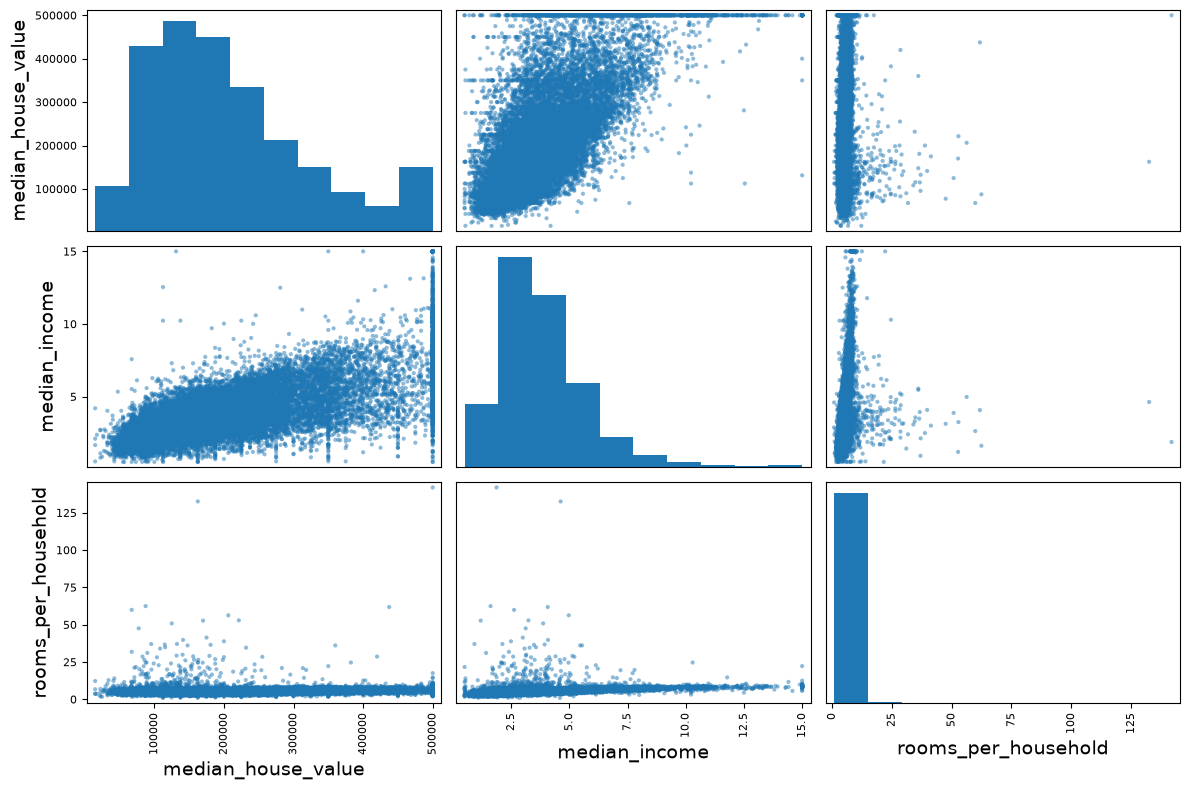

In [36]:
from pandas.plotting import scatter_matrix

attributes = ["median_house_value", "median_income", "rooms_per_household"]
scatter_matrix(housing[attributes], figsize=(12, 8))
plt.tight_layout()

In [38]:
# Mostrar las filas con al menos un valor nulo
housing[housing.isnull().any(axis=1)]

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household
290,-122.16,37.77,47.0,1256.0,NaN,570.0,218.0,4.3750,161900.0,NEAR BAY,5.761468,NaN,2.614679
341,-122.17,37.75,38.0,992.0,NaN,732.0,259.0,1.6196,85100.0,NEAR BAY,3.830116,NaN,2.826255
538,-122.28,37.78,29.0,5154.0,NaN,3741.0,1273.0,2.5762,173400.0,NEAR BAY,4.048704,NaN,2.938727
563,-122.24,37.75,45.0,891.0,NaN,384.0,146.0,4.9489,247100.0,NEAR BAY,6.102740,NaN,2.630137
696,-122.10,37.69,41.0,746.0,NaN,387.0,161.0,3.9063,178400.0,NEAR BAY,4.633540,NaN,2.403727
...,...,...,...,...,...,...,...,...,...,...,...,...,...
20267,-119.19,34.20,18.0,3620.0,NaN,3171.0,779.0,3.3409,220500.0,NEAR OCEAN,4.646983,NaN,4.070603
20268,-119.18,34.19,19.0,2393.0,NaN,1938.0,762.0,1.6953,167400.0,NEAR OCEAN,3.140420,NaN,2.543307
20372,-118.88,34.17,15.0,4260.0,NaN,1701.0,669.0,5.1033,410700.0,<1H OCEAN,6.367713,NaN,2.542601
20460,-118.75,34.29,17.0,5512.0,NaN,2734.0,814.0,6.6073,258100.0,<1H OCEAN,6.771499,NaN,3.358722


In [43]:
housing = housing.dropna(how='any').reset_index(drop=True)
housing.info()

<class 'pandas.DataFrame'>
RangeIndex: 20433 entries, 0 to 20432
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   longitude                 20433 non-null  float64
 1   latitude                  20433 non-null  float64
 2   housing_median_age        20433 non-null  float64
 3   total_rooms               20433 non-null  float64
 4   total_bedrooms            20433 non-null  float64
 5   population                20433 non-null  float64
 6   households                20433 non-null  float64
 7   median_income             20433 non-null  float64
 8   median_house_value        20433 non-null  float64
 9   ocean_proximity           20433 non-null  str    
 10  rooms_per_household       20433 non-null  float64
 11  bedrooms_per_room         20433 non-null  float64
 12  population_per_household  20433 non-null  float64
dtypes: float64(12), str(1)
memory usage: 2.0 MB


In [50]:
from sklearn.preprocessing import OneHotEncoder

cat_encoder = OneHotEncoder(sparse_output=False)
housing_cat = housing[['ocean_proximity']]
housing_cat_1hot = cat_encoder.fit_transform(housing_cat)
housing_cat_1hot_df = pd.DataFrame(housing_cat_1hot, columns=cat_encoder.categories_[0].tolist())
housing_cat_1hot_df

,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN
0,0.0,0.0,0.0,1.0,0.0
1,0.0,0.0,0.0,1.0,0.0
2,0.0,0.0,0.0,1.0,0.0
3,0.0,0.0,0.0,1.0,0.0
4,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...
20428,0.0,1.0,0.0,0.0,0.0
20429,0.0,1.0,0.0,0.0,0.0
20430,0.0,1.0,0.0,0.0,0.0
20431,0.0,1.0,0.0,0.0,0.0


In [51]:
housing_feats = housing.drop(columns='ocean_proximity')
housing_feats = pd.concat([housing_feats, housing_cat_1hot_df], axis=1)
housing_feats.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,rooms_per_household,bedrooms_per_room,population_per_household,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,6.984127,0.146591,2.555556,0.0,0.0,0.0,1.0,0.0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,6.238137,0.155797,2.109842,0.0,0.0,0.0,1.0,0.0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,8.288136,0.129516,2.802260,0.0,0.0,0.0,1.0,0.0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,5.817352,0.184458,2.547945,0.0,0.0,0.0,1.0,0.0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,6.281853,0.172096,2.181467,0.0,0.0,0.0,1.0,0.0


In [52]:
housing = load_housing_data() 
housing.info() 

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [55]:
housing.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,median_income_scaled
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000,2.064000e+04
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909,5.508083e-17
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874,1.000024e+00
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000,-1.774299e+00
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000,-6.881186e-01
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000,-1.767951e-01
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000,4.593063e-01
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000,5.858286e+00


In [56]:
# 1. Transformaciones: Escalar la variable median_income
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
housing['median_income_scaled'] = scaler.fit_transform(housing[['median_income']])
housing[['median_income', 'median_income_scaled']].head()  # Ver resultado

,median_income,median_income_scaled
0,8.3252,2.344766
1,8.3014,2.332238
2,7.2574,1.782699
3,5.6431,0.932968
4,3.8462,-0.012881


In [ ]:
# 2. Imputaciones: Rellenar valores nulos en total_bedrooms con la mediana
print("Valores nulos antes:", housing['total_bedrooms'].isnull().sum())
housing['total_bedrooms'] = housing['total_bedrooms'].fillna(housing['total_bedrooms'].median())
print("Valores nulos después:", housing['total_bedrooms'].isnull().sum())
housing[['total_bedrooms']].head(50)  # Ver resultado

Valores nulos antes: 207
Valores nulos después: 0


,total_bedrooms
0,129.0
1,1106.0
2,190.0
3,235.0
4,280.0
5,213.0
6,489.0
7,687.0
8,665.0
9,707.0


In [60]:
# 3. Sampleo: Tomar una muestra aleatoria del 10% de los datos
housing_sample = housing.sample(frac=0.1, random_state=42)
housing_sample.head()  # Ver muestra
housing_sample.info()  # Ver info de la muestra

<class 'pandas.DataFrame'>
Index: 2064 entries, 20046 to 13298
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   longitude             2064 non-null   float64
 1   latitude              2064 non-null   float64
 2   housing_median_age    2064 non-null   float64
 3   total_rooms           2064 non-null   float64
 4   total_bedrooms        2064 non-null   float64
 5   population            2064 non-null   float64
 6   households            2064 non-null   float64
 7   median_income         2064 non-null   float64
 8   median_house_value    2064 non-null   float64
 9   ocean_proximity       2064 non-null   str    
 10  median_income_scaled  2064 non-null   float64
dtypes: float64(10), str(1)
memory usage: 193.5 KB


In [61]:
# 4. Detección de atípicos: Detectar outliers en median_house_value usando el rango intercuartílico (IQR)
Q1 = housing['median_house_value'].quantile(0.25)
Q3 = housing['median_house_value'].quantile(0.75)
IQR = Q3 - Q1
outliers = housing[(housing['median_house_value'] < Q1 - 1.5 * IQR) | (housing['median_house_value'] > Q3 + 1.5 * IQR)]
outliers.head(50)  # Ver algunos outliers detectados

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,median_income_scaled
89,-122.27,37.80,52.0,249.0,78.0,396.0,85.0,1.2434,500001.0,NEAR BAY,-1.382937
140,-122.18,37.81,30.0,292.0,38.0,126.0,52.0,6.3624,483300.0,NEAR BAY,1.311591
459,-122.25,37.87,52.0,609.0,236.0,1349.0,250.0,1.1696,500001.0,NEAR BAY,-1.421784
489,-122.25,37.86,48.0,2153.0,517.0,1656.0,459.0,3.0417,489600.0,NEAR BAY,-0.436352
493,-122.24,37.86,52.0,1668.0,225.0,517.0,214.0,7.8521,500001.0,NEAR BAY,2.095736
494,-122.24,37.85,52.0,3726.0,474.0,1366.0,496.0,9.3959,500001.0,NEAR BAY,2.908359
509,-122.23,37.83,52.0,2990.0,379.0,947.0,361.0,7.8772,500001.0,NEAR BAY,2.108948
510,-122.22,37.82,39.0,2492.0,310.0,808.0,315.0,11.8603,500001.0,NEAR BAY,4.205564
511,-122.22,37.82,42.0,2991.0,335.0,1018.0,335.0,13.4990,500001.0,NEAR BAY,5.068140
512,-122.23,37.82,52.0,3242.0,366.0,1001.0,352.0,12.2138,500001.0,NEAR BAY,4.391639
